# Лабораторная работа №2. Функция влияния, точка срыва и смещение M-оценок

Работа состоит из трёх заданий.

1. Для модели сдвига логистического распределения вычисляются функции влияния и чувствительность к грубым ошибкам (gross-error sensitivity) стандартных оценок и M-оценок с ограниченной функцией $\psi$; моделированием проверяется, что асимптотическая дисперсия равна $\mathbb E_F\,\mathrm{IF}^2(X, F)$.
2. Для оценки Ходжеса–Лемана исследуется, насколько информативна оценка при долях выбросов меньше точки срыва, около неё и больше неё.
3. Для M-оценок сдвига нормального закона с предварительной оценкой масштаба MAD подбираются константы функций Хьюбера и bisquare по заданной асимптотической эффективности, вычисляются максимальное и асимптотическое смещение, затем — асимптотические дисперсии тех же оценок при распределении Коши.

Теоретические величины вычисляются численным интегрированием, результаты проверяются моделированием методом Монте-Карло.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate, optimize, special

MU = 3.0
NS = (50, 200, 1000)
R = 5000
SEED = 2026
Q75 = stats.norm.ppf(0.75)
MC_TOL = 3 * np.sqrt(2 / (R - 1))

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def rng_for(section):
    return np.random.default_rng([SEED, section])

## Распределения, функции ψ и оценки

Используются три закона: логистический (задания 1–2), нормальный (задание 3) и Коши (п. 3.5).

| закон | $f(u)$ | $F(u)$ |
|---|---|---|
| логистический | $\dfrac{e^{-u}}{(1+e^{-u})^2} = F(u)\bigl(1 - F(u)\bigr)$ | $\dfrac1{1+e^{-u}}$ |
| нормальный | $\varphi(u) = \dfrac{e^{-u^2/2}}{\sqrt{2\pi}}$ | $\Phi(u)$ |
| Коши | $\dfrac1{\pi(1+u^2)}$ | $\dfrac12 + \dfrac1\pi\operatorname{arctg}u$ |

Математические ожидания $\mathbb E_F g(U) = \int g f$ вычисляются адаптивной квадратурой с разбиением в точках излома $g$, как в лабораторной работе №1.

Функции $\psi$ M-оценок сдвига:

| $\psi$ | вид | $\psi'$ |
|---|---|---|
| Хьюбер | $\psi_k(u) = \max(-k, \min(u, k))$ | $\mathbb 1\{\lvert u\rvert \le k\}$ |
| bisquare | $\psi_c(u) = u\bigl(1 - (u/c)^2\bigr)^2\,\mathbb 1\{\lvert u\rvert \le c\}$ | $\bigl(1 - (u/c)^2\bigr)\bigl(1 - 5(u/c)^2\bigr)\,\mathbb 1\{\lvert u\rvert \le c\}$ |
| логистическая | $\psi_{\mathrm{ML}}(u) = -\dfrac{f'(u)}{f(u)} = \operatorname{th}\dfrac u2 = 2F(u) - 1$ | $\dfrac1{2\operatorname{ch}^2(u/2)} = 2f(u)$ |

M-оценка сдвига при масштабе $s$ — корень уравнения $\sum_i\psi\bigl((x_i - \mu)/s\bigr) = 0$. Он находится методом итеративно перевзвешенных наименьших квадратов (IRLS) с начальным приближением $\operatorname{med}(x)$: $\mu \leftarrow \sum w_ix_i/\sum w_i$, $w_i = \psi(r_i)/r_i$.

In [2]:
class Law:
    def expect(self, g, points=()):
        cuts = sorted({0.0, *(float(p) for p in points), *(-float(p) for p in points)})
        edges = [-np.inf, *cuts, np.inf]
        return sum(
            integrate.quad(lambda u: g(u) * self.pdf(u), a, b, limit=200, epsabs=1e-13, epsrel=1e-12)[0]
            for a, b in zip(edges[:-1], edges[1:])
        )


class Logistic(Law):
    def pdf(self, u):
        e = np.exp(-np.abs(u))
        return e / (1 + e) ** 2

    def cdf(self, u):
        return special.expit(u)

    def ppf(self, p):
        return special.logit(p)

    def rvs(self, size, rng):
        return rng.logistic(size=size)


class Normal(Law):
    def pdf(self, u):
        return np.exp(-0.5 * u * u) / np.sqrt(2 * np.pi)

    def cdf(self, u):
        return special.ndtr(u)

    def ppf(self, p):
        return special.ndtri(p)

    def rvs(self, size, rng):
        return rng.standard_normal(size)


class Cauchy(Law):
    def pdf(self, u):
        return 1 / (np.pi * (1 + u * u))

    def cdf(self, u):
        return 0.5 + np.arctan(u) / np.pi

    def ppf(self, p):
        return np.tan(np.pi * (p - 0.5))

    def rvs(self, size, rng):
        return rng.standard_cauchy(size)


LOGIS, NORM, CAUCHY = Logistic(), Normal(), Cauchy()


class Psi:
    points = ()

    def weight(self, u):
        safe = np.where(u == 0, 1.0, u)
        return np.where(u == 0, self.dpsi(0.0), self.psi(safe) / safe)


class Huber(Psi):
    def __init__(self, k):
        self.k, self.points = k, (k,)

    def psi(self, u):
        return np.clip(u, -self.k, self.k)

    def dpsi(self, u):
        return np.where(np.abs(u) <= self.k, 1.0, 0.0)


class Bisquare(Psi):
    def __init__(self, c):
        self.c, self.points = c, (c,)

    def psi(self, u):
        t = u / self.c
        return np.where(np.abs(t) <= 1, u * (1 - t * t) ** 2, 0.0)

    def dpsi(self, u):
        t = u / self.c
        return np.where(np.abs(t) <= 1, (1 - t * t) * (1 - 5 * t * t), 0.0)


class LogisticScore(Psi):
    def psi(self, u):
        return np.tanh(u / 2)

    def dpsi(self, u):
        return 0.5 * (1 - np.tanh(u / 2) ** 2)


def av_location(psi, law, theta=1.0):
    pts = [p * theta for p in psi.points]
    num = law.expect(lambda u: psi.psi(u / theta) ** 2, pts)
    den = law.expect(lambda u: psi.dpsi(u / theta), pts)
    return theta**2 * num / den**2


def m_location(x, psi, s=1.0, tol=1e-10, maxit=1000):
    s = np.asarray(s, dtype=float)[..., None]
    mu = np.median(x, axis=-1)
    for _ in range(maxit):
        w = psi.weight((x - mu[..., None]) / s)
        mu_new = np.sum(w * x, axis=-1) / np.sum(w, axis=-1)
        done = np.max(np.abs(mu_new - mu) / s[..., 0]) < tol
        mu = mu_new
        if done:
            return mu
    raise RuntimeError("M-location: no convergence")


def median(x):
    return np.median(x, axis=-1)


def trimmed_mean(alpha):
    return lambda x: stats.trim_mean(x, alpha, axis=-1)


def hodges_lehmann(x, block=10**7):
    n = x.shape[-1]
    i, j = np.triu_indices(n)
    flat = x.reshape(-1, n)
    step = max(1, block // len(i))
    out = np.empty(len(flat))
    for a in range(0, len(flat), step):
        b = flat[a : a + step]
        out[a : a + step] = np.median((b[:, i] + b[:, j]) / 2, axis=-1)
    return out.reshape(x.shape[:-1])


def madn(x):
    return np.median(np.abs(x - np.median(x, axis=-1, keepdims=True)), axis=-1) / Q75

In [3]:
assert all(abs(law.expect(lambda u: np.ones_like(u)) - 1) < 1e-10 for law in (LOGIS, NORM, CAUCHY))
assert abs(LOGIS.expect(lambda u: u * u) - np.pi**2 / 3) < 1e-9
assert abs(LOGIS.expect(lambda u: LogisticScore().psi(u) ** 2) - 1 / 3) < 1e-12
assert abs(LOGIS.expect(LogisticScore().dpsi) - 1 / 3) < 1e-12
for _psi in (Huber(1.345), Bisquare(4.685)):
    assert abs(1 / av_location(_psi, NORM) - 0.95) < 0.005
_x = LOGIS.rvs(41, rng_for(0))
assert np.isclose(hodges_lehmann(_x), np.median([(_x[i] + _x[j]) / 2 for i in range(41) for j in range(i, 41)]))
for _est in (median, trimmed_mean(0.1), hodges_lehmann, lambda x: m_location(x, Bisquare(4.685), madn(x))):
    assert np.isclose(_est(-3.7 * _x + 11.0), -3.7 * _est(_x) + 11.0, rtol=1e-8, atol=1e-8)
for _psi in (LogisticScore(), Huber(1.345), Bisquare(4.685)):
    assert np.isclose(m_location(_x + 11.0, _psi), m_location(_x, _psi) + 11.0, rtol=1e-8, atol=1e-8)
assert np.isclose(madn(-3.7 * _x + 11.0), 3.7 * madn(_x), rtol=1e-10)

## Задание 1. Функция влияния и чувствительность к грубым ошибкам

### 1.1. Модель и оценки

Рассматривается задача оценивания параметра сдвига
$$X_i = \mu + U_i,\qquad U_i \sim F,\quad F(u) = \frac1{1+e^{-u}},$$
масштаб известен и равен 1, в моделировании $\mu = 3$. Логистический закон симметричен, все его моменты конечны ($\operatorname{Var}U = \pi^2/3$), но хвосты тяжелее нормальных: $f(u) \sim e^{-\lvert u\rvert}$ против $e^{-u^2/2}$. Информация Фишера о сдвиге
$$I(F) = \int\Bigl(\frac{f'}{f}\Bigr)^2 f = \mathbb E\operatorname{th}^2\frac U2 = \frac13,$$
поэтому асимптотическая дисперсия регулярной оценки не меньше $1/I(F) = 3$.

Логистический закон выбран потому, что его оценка максимального правдоподобия — M-оценка с ограниченной функцией $\psi_{\mathrm{ML}} = \operatorname{th}(u/2)$: эффективная оценка здесь одновременно имеет ограниченную функцию влияния, чего нет у нормального закона (там ОМП — среднее). Нормальный закон рассматривается в задании 3.

| оценка | определение | тип |
|---|---|---|
| среднее | $\bar x$ | стандартная |
| медиана | $\operatorname{med}(x)$ | стандартная |
| усечённое среднее, $\alpha = 0.1$ | среднее без $\lfloor\alpha n\rfloor$ наименьших и $\lfloor\alpha n\rfloor$ наибольших наблюдений | стандартная (L-оценка) |
| Ходжес–Леман | $\operatorname{med}\{(x_i + x_j)/2:\ i \le j\}$ | стандартная (R-оценка) |
| ОМП | $\sum_i\psi_{\mathrm{ML}}(x_i - \mu) = 0$ | M-оценка, ограниченная $\psi$ |
| Хьюбер | $\sum_i\psi_k(x_i - \mu) = 0$, $k = 1.345$ | M-оценка, ограниченная $\psi$ |
| bisquare | $\sum_i\psi_c(x_i - \mu) = 0$, $c = 4.685$ | M-оценка, ограниченная $\psi$, $\psi = 0$ при $\lvert u\rvert > c$ |

Константы $k$ и $c$ стандартные (95% эффективности при нормальном законе). Все оценки эквивариантны относительно сдвига, поэтому функции влияния достаточно вычислить при $\mu = 0$: $\mathrm{IF}(x; \mu) = \mathrm{IF}(x - \mu; 0)$.

### 1.2. Функции влияния

Функция влияния функционала $T$ в точке $F$:
$$\mathrm{IF}(x; T, F) = \lim_{t\downarrow 0}\frac{T(F_t) - T(F)}{t},\qquad F_t = (1-t)F + t\delta_x.$$
Здесь $T(F) = 0$.

- **Среднее.** $T(F_t) = (1-t)\cdot 0 + tx$, откуда $\mathrm{IF}(x) = x$.
- **M-оценка.** $T(F_t)$ — корень уравнения $(1-t)\,\mathbb E_F\psi(U - T) + t\,\psi(x - T) = 0$. Дифференцируя по $t$ при $t = 0$ и учитывая $\mathbb E_F\psi(U) = 0$, получаем $\psi(x) - \mathrm{IF}(x)\,\mathbb E_F\psi'(U) = 0$, т.е.
  $$\mathrm{IF}(x) = \frac{\psi(x)}{\mathbb E_F\psi'(U)}.$$
  Для функции Хьюбера $\mathbb E\psi_k'(U) = 2F(k) - 1$, для bisquare знаменатель вычисляется численно.
- **ОМП.** $\psi_{\mathrm{ML}} = 2F - 1$, $\mathbb E\psi_{\mathrm{ML}}'(U) = 2\int f^2 = I(F) = 1/3$, поэтому $\mathrm{IF}(x) = 3\operatorname{th}(x/2)$.
- **Медиана** — M-оценка с $\psi = \operatorname{sign}$. Функция $\operatorname{sign}$ не дифференцируема, и $\mathbb E\psi'$ понимается как $-\frac{d}{dt}\mathbb E\operatorname{sign}(U - t)\big|_{t=0} = 2f(0)$: $\mathrm{IF}(x) = \dfrac{\operatorname{sign}x}{2f(0)} = 2\operatorname{sign}x$.
- **Усечённое среднее** $T(F) = \frac1{1-2\alpha}\int_\alpha^{1-\alpha}F^{-1}(p)\,dp$. Функция влияния квантили $\mathrm{IF}\bigl(x; F^{-1}(p)\bigr) = \dfrac{p - \mathbb 1\{x \le F^{-1}(p)\}}{f(F^{-1}(p))}$; интегрируя по $p \in [\alpha, 1-\alpha]$ с заменой $y = F^{-1}(p)$, получаем для симметричного $F$
  $$\mathrm{IF}(x) = \frac1{1-2\alpha}\int_{-q}^{q}\bigl(F(y) - \mathbb 1\{x \le y\}\bigr)\,dy = \frac{\psi_q(x)}{1 - 2\alpha},\qquad q = F^{-1}(1-\alpha) = \ln\frac{1-\alpha}\alpha = \ln 9,$$
  так как $\int_{-q}^qF = q$ и $\int_{-q}^q\mathbb 1\{x \le y\}\,dy = q - \psi_q(x)$. Функция влияния усечённого среднего пропорциональна функции Хьюбера с $k = q$.
- **Ходжес–Леман.** $T(G)$ — корень уравнения $\iint\mathbb 1\{y + z \le 2T\}\,dG(y)\,dG(z) = 1/2$. Для $G = F_t$ левая часть равна
  $$(1-t)^2\int F(2T - y)\,dF(y) + 2t(1-t)F(2T - x) + t^2\,\mathbb 1\{x \le T\}.$$
  Дифференцируя при $t = 0$ и пользуясь симметрией ($\int F(-y)\,dF(y) = 1/2$), получаем $-1 + 2F(-x) + 2\,\mathrm{IF}(x)\int f^2 = 0$:
  $$\mathrm{IF}(x) = \frac{F(x) - 1/2}{\int f^2(y)\,dy}.$$
  Для логистического закона $\int f^2 = \int_0^1 p(1-p)\,dp = 1/6$ (замена $p = F(y)$, $f = p(1-p)$), поэтому $\mathrm{IF}(x) = 6\bigl(F(x) - 1/2\bigr) = 3\operatorname{th}(x/2)$ — та же функция влияния, что у ОМП. Значит, оценка Ходжеса–Лемана асимптотически эффективна для логистического закона.

In [4]:
ALPHA = 0.1
Q_TRIM = LOGIS.ppf(1 - ALPHA)
INT_F2 = LOGIS.expect(LOGIS.pdf)
PSI1 = {"ОМП": LogisticScore(), "Хьюбер 1.345": Huber(1.345), "bisquare 4.685": Bisquare(4.685)}
D1 = {name: LOGIS.expect(psi.dpsi, psi.points) for name, psi in PSI1.items()}

ESTIMATORS1 = {
    "среднее": lambda x: x.mean(axis=-1),
    "медиана": median,
    "усечённое среднее 0.1": trimmed_mean(ALPHA),
    "Ходжес–Леман": hodges_lehmann,
} | {name: (lambda x, psi=psi: m_location(x, psi)) for name, psi in PSI1.items()}

IF1 = {
    "среднее": lambda u: u,
    "медиана": lambda u: np.sign(u) / (2 * LOGIS.pdf(0.0)),
    "усечённое среднее 0.1": lambda u: np.clip(u, -Q_TRIM, Q_TRIM) / (1 - 2 * ALPHA),
    "Ходжес–Леман": lambda u: (LOGIS.cdf(u) - 0.5) / INT_F2,
} | {name: (lambda u, psi=psi, d=D1[name]: psi.psi(u) / d) for name, psi in PSI1.items()}
IF_POINTS = {"усечённое среднее 0.1": (Q_TRIM,)} | {name: psi.points for name, psi in PSI1.items()}

assert abs(Q_TRIM - np.log(9)) < 1e-12 and abs(INT_F2 - 1 / 6) < 1e-12
assert abs(D1["Хьюбер 1.345"] - (2 * LOGIS.cdf(1.345) - 1)) < 1e-12
_g = np.linspace(-20, 20, 4001)
assert np.allclose(IF1["Ходжес–Леман"](_g), 3 * np.tanh(_g / 2), atol=1e-12)
assert np.allclose(IF1["ОМП"](_g), 3 * np.tanh(_g / 2), atol=1e-12)

Аналитические функции влияния сравниваются с кривой чувствительности Тьюки
$$\mathrm{SC}_n(x) = (n+1)\bigl(T_{n+1}(x_1, \dots, x_n, x) - T_n(x_1, \dots, x_n)\bigr).$$
Это конечный аналог определения функции влияния с $t = 1/(n+1)$ и эмпирической функцией распределения вместо $F$; $\mathrm{SC}_n \to \mathrm{IF}$ при $n \to \infty$. Кривая вычисляется на «стилизованной» выборке $x_i = F^{-1}\bigl(i/(n+1)\bigr)$, $n = 999$, у которой нет случайного разброса.

Для оценки Ходжеса–Лемана стилизованная выборка непригодна. Она симметрична, поэтому $(n+1)/2 = 500$ средних Уолша $(x_i + x_{n+1-i})/2$ равны нулю. Медиана средних Уолша попадает в этот атом и не сдвигается, пока новое наблюдение не добавит по одну сторону от нуля достаточно много средних, — кривая равна нулю при $\lvert x\rvert \lesssim 1$. Несимметричные регулярные сетки дают тот же эффект в ослабленном виде: их средние Уолша образуют решётку. Поэтому для этой оценки кривая чувствительности усредняется по 30 случайным выборкам того же объёма.

In [5]:
N_SC = 999
_base = LOGIS.ppf(np.arange(1, N_SC + 1) / (N_SC + 1))
SC_GRID = np.linspace(-7.95, 7.95, 160)
_X = np.column_stack([np.tile(_base, (len(SC_GRID), 1)), SC_GRID])
SC = {name: (N_SC + 1) * (est(_X) - est(_base)) for name, est in ESTIMATORS1.items() if name != "Ходжес–Леман"}
assert np.all(np.abs(SC_GRID[70:90]) < 1)
assert np.all(np.abs(hodges_lehmann(_X[70:90]) - hodges_lehmann(_base)) < 1e-12)

_rng = rng_for(11)
_hl = []
for _ in range(30):
    _b = LOGIS.rvs(N_SC, _rng)
    _hl.append((N_SC + 1) * (hodges_lehmann(np.column_stack([np.tile(_b, (len(SC_GRID[::5]), 1)), SC_GRID[::5]])) - hodges_lehmann(_b)))
SC_HL = np.mean(_hl, axis=0)

sc_err = pd.Series({name: np.max(np.abs(sc - IF1[name](SC_GRID))) for name, sc in SC.items()})
sc_err["Ходжес–Леман (среднее по 30 выборкам)"] = np.max(np.abs(SC_HL - IF1["Ходжес–Леман"](SC_GRID[::5])))
assert (sc_err.drop("Ходжес–Леман (среднее по 30 выборкам)") < 0.01).all() and sc_err.iloc[-1] < 0.06
sc_err.to_frame("max |SC − IF|")

,max |SC − IF|
среднее,0.0000
медиана,0.0000
усечённое среднее 0.1,0.0000
ОМП,0.0017
Хьюбер 1.345,0.0046
bisquare 4.685,0.0030
Ходжес–Леман (среднее по 30 выборкам),0.0336


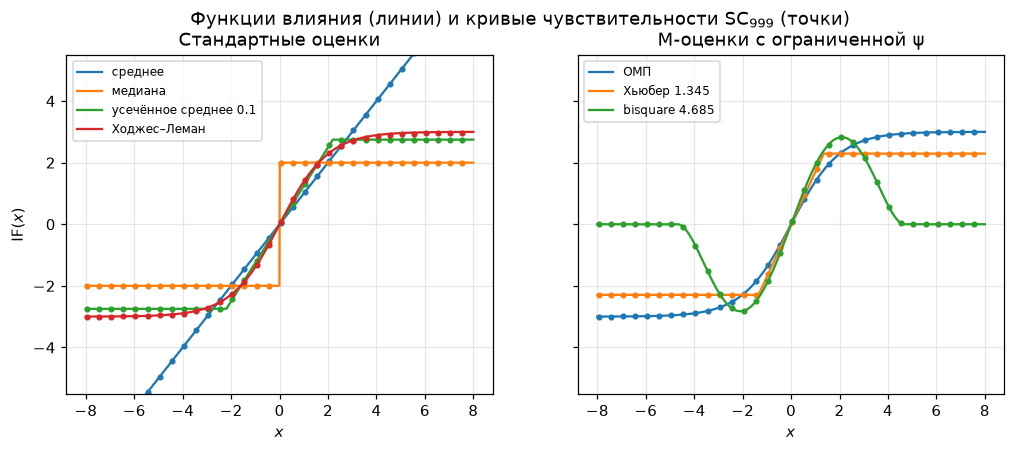

In [6]:
_groups = {"Стандартные оценки": list(ESTIMATORS1)[:4], "M-оценки с ограниченной ψ": list(PSI1)}
_u = np.linspace(-8, 8, 1601)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (title, names) in zip(axes, _groups.items()):
    for i, name in enumerate(names):
        ax.plot(_u, IF1[name](_u), color=f"C{i}", label=name)
        sc = SC_HL if name == "Ходжес–Леман" else SC[name][::5]
        ax.plot(SC_GRID[::5], sc, "o", ms=3, color=f"C{i}")
    ax.set_title(title)
    ax.set_xlabel("$x$")
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel(r"$\mathrm{IF}(x)$")
axes[0].set_ylim(-5.5, 5.5)
fig.suptitle(r"Функции влияния (линии) и кривые чувствительности $\mathrm{SC}_{999}$ (точки)")
plt.show()

Расхождение кривых чувствительности с аналитическими функциями влияния не превышает 0.005 (для оценки Ходжеса–Лемана, где кривая усреднена по случайным выборкам, — 0.034). По виду функции влияния оценки делятся на три группы:

- среднее: IF линейна и не ограничена — одно наблюдение может сдвинуть оценку сколь угодно далеко;
- медиана, усечённое среднее, Ходжес–Леман, ОМП и Хьюбер: IF ограничена и не убывает — влияние далёкого наблюдения ограничено, но не исчезает (у Хьюбера и усечённого среднего далёкое наблюдение действует как наблюдение на границе зоны линейности);
- bisquare: IF ограничена и равна нулю при $\lvert x\rvert > c$ — наблюдения дальше $c = 4.685$ от центра на оценку не влияют.

Функции влияния усечённого среднего и оценки Хьюбера отличаются только точкой обрезания ($q = \ln 9 \approx 2.20$ против $k = 1.345$) и нормировкой. У медианы IF разрывна в нуле: малое изменение центрального наблюдения может заметно сдвинуть оценку.

### 1.3. Gross-error sensitivity

$$\gamma^* = \sup_x\lvert\mathrm{IF}(x; T, F)\rvert$$
— наибольшее влияние, которое одно наблюдение (бесконечно малая доля засорения) может оказать на оценку; оценки с $\gamma^* < \infty$ называют B-робастными. Для рассматриваемых оценок:

- среднее: $\gamma^* = \infty$;
- медиана: $\gamma^* = 1/(2f(0)) = 2$;
- усечённое среднее: $\gamma^* = q/(1-2\alpha) = \ln 9/0.8$;
- Ходжес–Леман и ОМП: $\gamma^* = \lim_{x\to\infty}3\operatorname{th}(x/2) = 3$ (супремум не достигается);
- Хьюбер: $\gamma^* = k/(2F(k) - 1)$;
- bisquare: $\lvert\psi_c\rvert$ максимальна при $u = c/\sqrt5$, откуда $\gamma^* = \dfrac{16c}{25\sqrt5\,\mathbb E\psi_c'(U)}$.

Для симметричной унимодальной плотности медиана имеет наименьшую $\gamma^*$ среди всех эквивариантных оценок сдвига. Дифференцируя тождество $T\bigl(F(\cdot - \theta)\bigr) = \theta$ по $\theta$ при $\theta = 0$, получаем $-\int\mathrm{IF}(x)f'(x)\,dx = 1$, откуда
$$1 \le \gamma^*\int\lvert f'\rvert = 2f(0)\,\gamma^*,\qquad \gamma^* \ge \frac1{2f(0)}.$$

Для полноты приведены ещё две характеристики Хампеля: чувствительность к локальному сдвигу $\lambda^* = \sup_{x \ne y}\lvert\mathrm{IF}(y) - \mathrm{IF}(x)\rvert/\lvert y - x\rvert$ (реакция на малое изменение одного наблюдения, например округление) и точка отбрасывания $\rho^* = \inf\{r:\ \mathrm{IF}(x) = 0\ \text{при}\ \lvert x\rvert > r\}$.

In [7]:
_wide = np.linspace(-60, 60, 1_200_001)
GES1 = {
    "среднее": np.inf,
    "медиана": 1 / (2 * LOGIS.pdf(0.0)),
    "усечённое среднее 0.1": Q_TRIM / (1 - 2 * ALPHA),
    "Ходжес–Леман": 0.5 / INT_F2,
    "ОМП": 1 / D1["ОМП"],
    "Хьюбер 1.345": 1.345 / D1["Хьюбер 1.345"],
    "bisquare 4.685": 16 * 4.685 / (25 * np.sqrt(5)) / D1["bisquare 4.685"],
}
LSS1 = {
    "среднее": 1.0,
    "медиана": np.inf,
    "усечённое среднее 0.1": 1 / (1 - 2 * ALPHA),
    "Ходжес–Леман": LOGIS.pdf(0.0) / INT_F2,
    "ОМП": 0.5 / D1["ОМП"],
    "Хьюбер 1.345": 1 / D1["Хьюбер 1.345"],
    "bisquare 4.685": 1 / D1["bisquare 4.685"],
}
REJ1 = {name: np.inf for name in ESTIMATORS1} | {"bisquare 4.685": 4.685}

for name, fn in IF1.items():
    vals = fn(_wide)
    if np.isfinite(GES1[name]):
        assert abs(np.max(np.abs(vals)) - GES1[name]) < 1e-6, name
    if np.isfinite(LSS1[name]):
        assert abs(np.max(np.abs(np.diff(vals) / np.diff(_wide))) - LSS1[name]) < 1e-3, name
assert np.all(IF1["bisquare 4.685"](_wide[np.abs(_wide) > 4.685]) == 0)
assert all(g >= GES1["медиана"] for g in GES1.values())
pd.DataFrame({"γ* (GES)": GES1, "λ* (local shift)": LSS1, "ρ* (rejection point)": REJ1})

,γ* (GES),λ* (local shift),ρ* (rejection point)
среднее,inf,1.0000,inf
медиана,2.0000,inf,inf
усечённое среднее 0.1,2.7465,1.2500,inf
Ходжес–Леман,3.0000,1.5000,inf
ОМП,3.0000,1.5000,inf
Хьюбер 1.345,2.2928,1.7047,inf
bisquare 4.685,2.8250,2.1067,4.6850


Все ограниченные функции влияния имеют $\gamma^* \ge 2$, минимум достигается у медианы, как и следует из неравенства выше. Наибольшая $\gamma^*$ среди B-робастных оценок — у ОМП и оценки Ходжеса–Лемана ($\gamma^* = 3$): за эффективность при логистическом законе приходится платить бóльшим влиянием далёких наблюдений. Оценка Хьюбера с $k = 1.345$ — компромисс: $\gamma^* \approx 2.29$ при эффективности 97% (п. 1.4).

Bisquare — единственная оценка с конечной точкой отбрасывания $\rho^* = c$. Её $\gamma^* \approx 2.83$ и $\lambda^* \approx 2.11$ велики из-за малого знаменателя $\mathbb E\psi_c'(U) \approx 0.47$: константа $c = 4.685$ рассчитана на нормальный закон, а у логистического закона хвосты тяжелее — около 20% наблюдений попадает на убывающий участок $c/\sqrt5 < \lvert u\rvert \le c$, где $\psi_c' < 0$, и ещё 2% — за точку отбрасывания. У медианы $\lambda^* = \infty$ из-за разрыва IF в нуле.

### 1.4. Асимптотическая дисперсия и $\mathbb E_F\,\mathrm{IF}^2$

Если функционал $T$ достаточно гладкий (дифференцируем по Адамару), справедливо линейное представление
$$T(F_n) = T(F) + \frac1n\sum_{i=1}^n\mathrm{IF}(X_i; T, F) + o_P(n^{-1/2}),\qquad \mathbb E_F\,\mathrm{IF}(X; T, F) = 0,$$
и по центральной предельной теореме
$$\sqrt n\bigl(T(F_n) - T(F)\bigr) \Rightarrow N(0, v^2),\qquad v^2 = \mathbb E_F\,\mathrm{IF}^2(X; T, F).$$
Для M-оценок отсюда получается формула $v^2 = \mathbb E\psi^2/(\mathbb E\psi')^2$, для медианы $v^2 = 1/(4f^2(0)) = 4$, для оценок Ходжеса–Лемана и ОМП $v^2 = 9\,\mathbb E\operatorname{th}^2(U/2) = 3 = 1/I(F)$. Асимптотическая эффективность оценки равна $1/(I(F)\,v^2) = 3/v^2$.

Проверка моделированием: для $n \in \{50, 200, 1000\}$ генерируется по $R = 5000$ выборок, $n\,\widehat{\operatorname{Var}}(T_n)$ сравнивается с $v^2 = \mathbb E_F\,\mathrm{IF}^2$, вычисленным интегрированием. Кроме того, при $n = 1000$:

- вычисляется среднее $\mathrm{IF}^2(X_i - \mu)$ по всем $R\cdot n$ наблюдениям — оценка $\mathbb E_F\,\mathrm{IF}^2$ методом Монте-Карло;
- для каждой выборки вычисляется линейная часть $L_n = n^{-1/2}\sum_i\mathrm{IF}(X_i - \mu)$ и её корреляция с $\sqrt n(T_n - \mu)$; корреляция, близкая к 1, означает, что разброс оценки действительно порождается суммой функций влияния.

In [8]:
V2 = {name: LOGIS.expect(lambda u, fn=fn: fn(u) ** 2, IF_POINTS.get(name, ())) for name, fn in IF1.items()}
assert abs(V2["среднее"] - np.pi**2 / 3) < 1e-9 and abs(V2["медиана"] - 4) < 1e-9
assert abs(V2["Ходжес–Леман"] - 3) < 1e-9 and abs(V2["ОМП"] - 3) < 1e-9
for _name, _psi in PSI1.items():
    assert abs(V2[_name] - av_location(_psi, LOGIS)) < 1e-9
assert all(abs(LOGIS.expect(fn, IF_POINTS.get(name, ()))) < 1e-10 for name, fn in IF1.items())

_rng = rng_for(1)
_rows = []
LAST1 = {}
for n in NS:
    X = MU + LOGIS.rvs((R, n), _rng)
    for name, est in ESTIMATORS1.items():
        t = est(X)
        row = {"n": n, "оценка": name, "смещение": t.mean() - MU, "n·Var (MC)": n * t.var(ddof=1)}
        if n == NS[-1]:
            ifx = IF1[name](X - MU)
            lin = ifx.sum(axis=-1) / np.sqrt(n)
            row["mean IF²(Xᵢ)"] = np.mean(ifx**2)
            row["corr"] = np.corrcoef(np.sqrt(n) * (t - MU), lin)[0, 1]
            LAST1[name] = (np.sqrt(n) * (t - MU), lin)
        _rows.append(row)
if_mc = pd.DataFrame(_rows)

_last = if_mc[if_mc["n"] == NS[-1]].set_index("оценка")
_v2 = pd.Series(V2)
assert (abs(_last["n·Var (MC)"] / _v2 - 1) < MC_TOL).all()
assert (abs(_last["mean IF²(Xᵢ)"] / _v2 - 1) < 0.002).all()
assert (_last["corr"].drop("медиана") > 0.999).all() and _last.loc["медиана", "corr"] > 0.97
assert (abs(_last["смещение"]) < 4 * np.sqrt(_v2 / (NS[-1] * R))).all()

_tab = if_mc.pivot(index="оценка", columns="n", values="n·Var (MC)").loc[list(ESTIMATORS1)]
_tab.columns = [f"n·Var, n={n}" for n in _tab.columns]
_tab["E IF² (теория)"] = _v2
_tab["mean IF²(Xᵢ), MC"] = _last["mean IF²(Xᵢ)"]
_tab["corr(√n(Tₙ−μ), Lₙ)"] = _last["corr"]
_tab["эффективность 3/v²"] = 3 / _v2
_tab

,"n·Var, n=50","n·Var, n=200","n·Var, n=1000",E IF² (теория),"mean IF²(Xᵢ), MC","corr(√n(Tₙ−μ), Lₙ)",эффективность 3/v²
оценка,,,,,,,
среднее,3.3320,3.2882,3.3668,3.2899,3.2901,1.0000,0.9119
медиана,3.9364,3.9313,4.2116,4.0000,4.0000,0.9772,0.7500
усечённое среднее 0.1,3.0917,3.0064,3.0952,3.0175,3.0185,0.9998,0.9942
Ходжес–Леман,3.0867,2.9911,3.0812,3.0000,3.0013,0.9998,1.0000
ОМП,3.0697,2.9834,3.0822,3.0000,3.0013,0.9999,1.0000
Хьюбер 1.345,3.1538,3.0716,3.1809,3.0891,3.0904,0.9997,0.9712
bisquare 4.685,3.6688,3.5593,3.6951,3.5665,3.5674,0.9994,0.8412


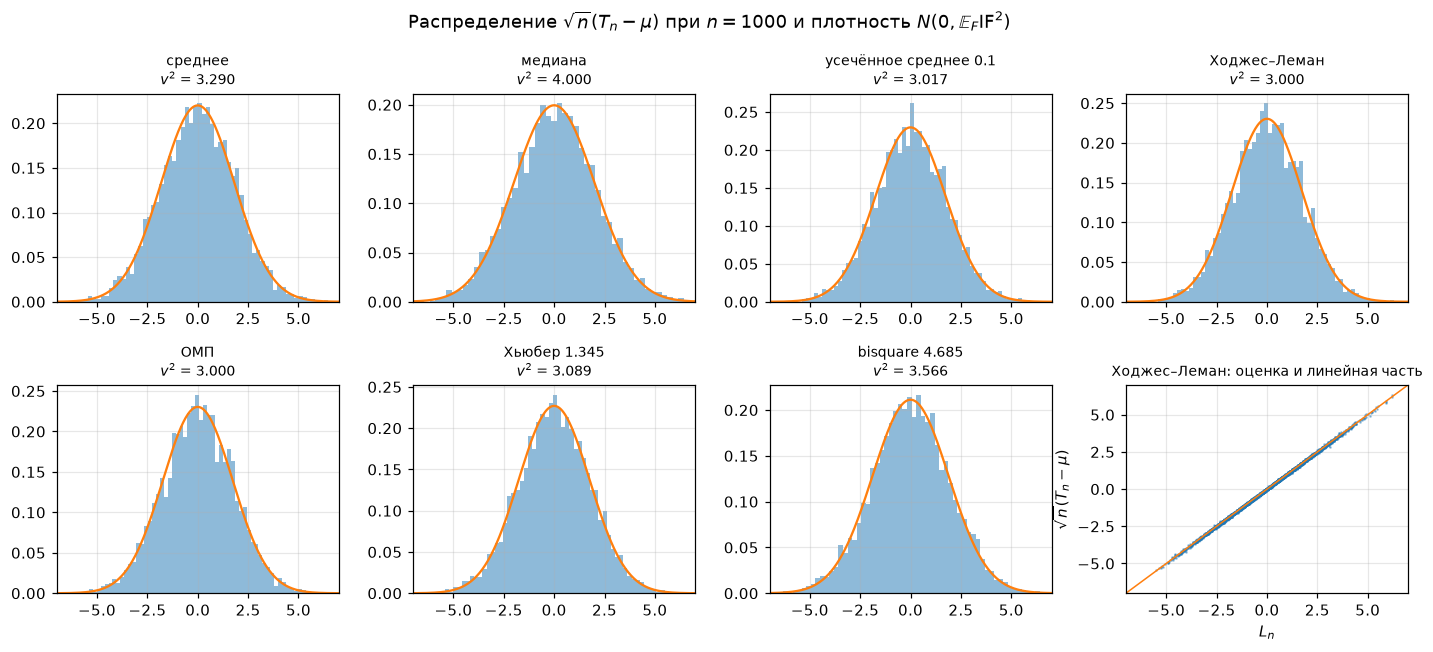

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
_z = np.linspace(-7, 7, 400)
for ax, name in zip(axes.flat, ESTIMATORS1):
    ax.hist(LAST1[name][0], bins=60, density=True, color="C0", alpha=0.5)
    ax.plot(_z, stats.norm.pdf(_z, scale=np.sqrt(V2[name])), color="C1")
    ax.set_title(f"{name}\n$v^2$ = {V2[name]:.3f}", fontsize=9)
    ax.set_xlim(-7, 7)
_ax = axes.flat[-1]
_t, _l = LAST1["Ходжес–Леман"]
_ax.plot(_l, _t, ".", ms=1.5, alpha=0.4)
_ax.plot([-7, 7], [-7, 7], color="C1", lw=1)
_ax.set_xlim(-7, 7)
_ax.set_ylim(-7, 7)
_ax.set_xlabel("$L_n$")
_ax.set_ylabel(r"$\sqrt{n}(T_n - \mu)$")
_ax.set_title("Ходжес–Леман: оценка и линейная часть", fontsize=9)
fig.suptitle(r"Распределение $\sqrt{n}(T_n - \mu)$ при $n = 1000$ и плотность $N(0, \mathbb{E}_F\mathrm{IF}^2)$")
fig.tight_layout()
plt.show()

При $n = 1000$ величина $n\,\widehat{\operatorname{Var}}(T_n)$ у всех оценок согласуется с $\mathbb E_F\,\mathrm{IF}^2$ в пределах погрешности моделирования (порог $3\sqrt{2/(R-1)} \approx 6\%$), при $n = 200$ отклонения не превышают 1.7%. Отклонения при $n = 1000$ у всех оценок одного знака: оценки вычисляются по одним и тем же выборкам и сильно коррелированы, поэтому случайная ошибка у них общая. Среднее $\mathrm{IF}^2(X_i)$ по $5\cdot10^6$ наблюдениям совпадает с интегралом с точностью 0.05%.

Корреляция $\sqrt n(T_n - \mu)$ с линейной частью $L_n$ превышает 0.999 у всех оценок, кроме медианы ($\approx 0.977$): у медианы остаточный член представления Бахадура в масштабе $\sqrt n$ убывает лишь как $n^{-1/4}$. Гистограммы $\sqrt n(T_n - \mu)$ согласуются с плотностями $N(0, \mathbb E_F\,\mathrm{IF}^2)$, а на последнем графике точки $\bigl(L_n, \sqrt n(T_n - \mu)\bigr)$ для оценки Ходжеса–Лемана лежат на диагонали. Таким образом, асимптотическая дисперсия действительно равна $v^2 = \mathbb E_F\,\mathrm{IF}^2$.

По эффективности при логистическом законе оценки упорядочены так: Ходжес–Леман и ОМП (1.00), усечённое среднее (0.994), Хьюбер (0.971), среднее (0.912), bisquare (0.841), медиана (0.75). Bisquare с $c = 4.685$ здесь проигрывает даже среднему: константа подобрана для нормального закона, а логистический закон с единичным масштабом имеет стандартное отклонение $\pi/\sqrt3 \approx 1.81$ и более тяжёлые хвосты, поэтому bisquare даёт малый вес слишком многим «хорошим» наблюдениям.

## Задание 2. Информативность оценки и точка срыва

### 2.1. Оценка и её точка срыва

Точка срыва функционала $T$ в точке $F$ — наибольшая доля засорения, при которой смещение остаётся ограниченным:
$$\varepsilon^* = \sup\Bigl\{\varepsilon:\ \sup_G\bigl\lvert T\bigl((1-\varepsilon)F + \varepsilon G\bigr)\bigr\rvert < \infty\Bigr\}.$$
Конечновыборочная точка срыва (замещение): $\varepsilon_n^* = \min\{m/n:\ \sup\lvert T_n(x')\rvert = \infty\}$, где супремум берётся по всем выборкам $x'$, полученным из $x$ заменой $m$ наблюдений произвольными значениями.

Исследуется оценка Ходжеса–Лемана из задания 1. Пусть доля $\varepsilon$ наблюдений уходит в $+\infty$. Тогда в $+\infty$ уходят все средние Уолша $(x_i + x_j)/2$, содержащие хотя бы одно такое наблюдение, — асимптотически доля $1 - (1-\varepsilon)^2$. Медиана средних Уолша остаётся ограниченной, пока конечных средних больше половины: $(1-\varepsilon)^2 > 1/2$, т.е.
$$\varepsilon^*_{\mathrm{HL}} = 1 - \frac1{\sqrt2} \approx 0.293.$$
При конечном $n$ из $N = n(n+1)/2$ средних Уолша конечны $K_m = (n-m)(n-m+1)/2$, и выборочная медиана ограничена, пока $K_m \ge \lfloor N/2\rfloor + 1$.

Для сравнения рассматриваются оценки с другими точками срыва: усечённые средние с $\alpha = 0.1$ и $\alpha = 0.25$ ($\varepsilon^* = \alpha$, $\varepsilon_n^* = (\lfloor\alpha n\rfloor + 1)/n$) и медиана ($\varepsilon^* = 1/2$, $\varepsilon_n^* = \lceil n/2\rceil/n$). Все четыре оценки не убывают по каждому наблюдению, поэтому наихудшее засорение для них — перенос наблюдений в $+\infty$ (или $-\infty$). Модель — логистическая, как в задании 1, объём выборки $n = 100$.

In [10]:
N2 = 100
TRIM2 = {"усечённое среднее 0.1": 0.1, "усечённое среднее 0.25": 0.25}
EST2 = {name: trimmed_mean(a) for name, a in TRIM2.items()} | {"Ходжес–Леман": hodges_lehmann, "медиана": median}
BP = TRIM2 | {"Ходжес–Леман": 1 - 1 / np.sqrt(2), "медиана": 0.5}


def bp_n_hl(n):
    need = n * (n + 1) // 2 // 2 + 1
    return next(m for m in range(n + 1) if (n - m) * (n - m + 1) // 2 < need) / n


def bp_n_empirical(est, x, far=1e12):
    for m in range(len(x) + 1):
        y = x.copy()
        y[:m] = far
        if abs(est(y)) > 1e6:
            return m / len(x)


BP_N = {name: (int(a * N2) + 1) / N2 for name, a in TRIM2.items()} | {
    "Ходжес–Леман": bp_n_hl(N2),
    "медиана": (N2 + 1) // 2 / N2,
}
_x = LOGIS.rvs(N2, rng_for(20))
bp_tab = pd.DataFrame({
    "ε*": BP,
    f"ε*_n, n = {N2}": BP_N,
    "ε*_n, эксперимент": {name: bp_n_empirical(est, _x) for name, est in EST2.items()},
})
assert (bp_tab.iloc[:, 1] == bp_tab.iloc[:, 2]).all()
bp_tab

,ε*,"ε*_n, n = 100","ε*_n, эксперимент"
усечённое среднее 0.1,0.1000,0.1100,0.1100
усечённое среднее 0.25,0.2500,0.2600,0.2600
Ходжес–Леман,0.2929,0.3000,0.3000
медиана,0.5000,0.5000,0.5000


### 2.2. Что считать информативностью

Ниже точки срыва оценка информативна: при любых значениях выбросов её смещение не превосходит максимального смещения
$$B(\varepsilon) = \sup_G\bigl\lvert T\bigl((1-\varepsilon)F + \varepsilon G\bigr) - T(F)\bigr\rvert < \infty,$$
поэтому по значению оценки параметр восстанавливается с точностью до $B(\varepsilon)$ плюс статистическая погрешность. При $\varepsilon > \varepsilon^*$ выбросы могут перенести оценку в любую точку, и её значение ничего не говорит о $\mu$. Информативность исследуется тремя способами:

1. смещение в зависимости от удалённости выбросов $d$ при фиксированной доле $\varepsilon$: ниже точки срыва оно ограничено по $d$, выше — растёт вместе с $d$;
2. максимальное смещение $B(\varepsilon)$ как функция отношения $\varepsilon/\varepsilon^*$;
3. доля дисперсии оценки, объясняемая параметром: $\mu$ выбирается случайно, выбросы располагаются далеко в случайных местах, и вычисляется $\rho^2 = \operatorname{corr}^2(T_n, \mu)$. Значение $\rho^2 \approx 1$ означает, что оценка следует за параметром, $\rho^2 \approx 0$ — что она определяется выбросами и о $\mu$ ничего не сообщает.

### 2.3. Смещение и удалённость выбросов

В выборках объёма $n = 100$ из логистического закона первые $m$ наблюдений заменяются на $\mu + d$, $d \in [1, 10^4]$; для всех пар $(m, d)$ используются одни и те же 500 выборок. Значения $m$ выбраны вокруг $n\varepsilon^*_n = 30$.

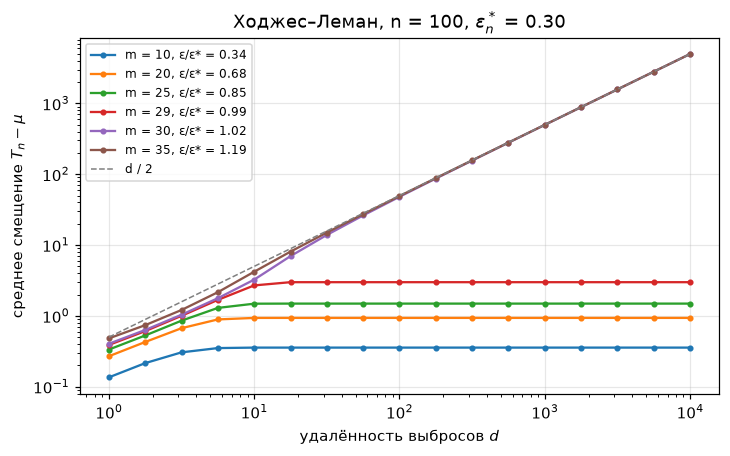

,10,20,25,29,30,35
d,,,,,,
1.0000,0.1353,0.2689,0.3342,0.3882,0.4033,0.4805
10.0000,0.3561,0.9351,1.4853,2.6914,3.2457,4.1989
100.0000,0.3561,0.9356,1.4894,2.9887,48.0826,49.1859
1000.0000,0.3561,0.9356,1.4894,2.9887,498.0826,499.1859
10000.0000,0.3561,0.9356,1.4894,2.9887,4998.0826,4999.1859


In [11]:
M_LIST = (10, 20, 25, 29, 30, 35)
D_GRID = np.logspace(0, 4, 17)
_X0 = MU + LOGIS.rvs((500, N2), rng_for(21))
_bias = {}
for m in M_LIST:
    for d in D_GRID:
        X = _X0.copy()
        X[:, :m] = MU + d
        _bias[(m, d)] = hodges_lehmann(X).mean() - MU
bias_d = pd.Series(_bias).unstack(0)
assert (bias_d.loc[:, [m for m in M_LIST if m / N2 < BP_N["Ходжес–Леман"]]].iloc[-1] < 10).all()
assert (bias_d.loc[:, [m for m in M_LIST if m / N2 >= BP_N["Ходжес–Леман"]]].iloc[-1] > 1000).all()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for m in M_LIST:
    ax.loglog(D_GRID, bias_d[m], marker="o", ms=3, label=f"m = {m}, ε/ε* = {m / N2 / BP['Ходжес–Леман']:.2f}")
ax.loglog(D_GRID, D_GRID / 2, color="gray", ls="--", lw=1, label="d / 2")
ax.set_xlabel("удалённость выбросов $d$")
ax.set_ylabel(r"среднее смещение $T_n - \mu$")
ax.set_title(f"Ходжес–Леман, n = {N2}, $\\varepsilon^*_n$ = {BP_N['Ходжес–Леман']:.2f}")
ax.legend(fontsize=8)
plt.show()
bias_d.iloc[[0, 4, 8, 12, 16]].rename_axis("d")

Пока $m \le 29$ ($\varepsilon < \varepsilon^*_n = 0.30$), смещение растёт с удалённостью выбросов лишь до $d \approx 10$–$100$, а затем перестаёт зависеть от $d$: далёкие выбросы влияют на оценку своим количеством, но не значением. Уровень плато быстро растёт при приближении к точке срыва: 0.36 при $m = 10$, 0.94 при $m = 20$, 1.49 при $m = 25$ и 2.99 при $m = 29$ — в 17 раз больше стандартной ошибки $\sqrt{3/100} \approx 0.17$. При $m \ge 30$ смещение растёт как $d/2 - \mathrm{const}$ (при $m = 30$ константа около 1.9): медиана средних Уолша попадает в средние вида $(x_i + \mu + d)/2$, т.е. оценку определяют выбросы.

### 2.4. Максимальное смещение

Для засорения $G = \delta_{+\infty}$ функционалы вычисляются явно:

- медиана: $(1-\varepsilon)F(T) = 1/2$, откуда $B(\varepsilon) = F^{-1}\Bigl(\dfrac1{2(1-\varepsilon)}\Bigr)$;
- усечённое среднее при $\varepsilon < \alpha$: квантильная функция смеси на $(0, 1-\varepsilon)$ равна $F^{-1}\bigl(p/(1-\varepsilon)\bigr)$, поэтому
  $$B(\varepsilon) = \frac{1-\varepsilon}{1-2\alpha}\int_{\alpha/(1-\varepsilon)}^{(1-\alpha)/(1-\varepsilon)}F^{-1}(v)\,dv,\qquad \int F^{-1}(v)\,dv = v\ln v + (1-v)\ln(1-v);$$
- Ходжес–Леман: $(1-\varepsilon)^2F_2(2T) = 1/2$, где $F_2$ — функция распределения $U_1 + U_2$, т.е. $B(\varepsilon) = \frac12F_2^{-1}\Bigl(\dfrac1{2(1-\varepsilon)^2}\Bigr)$.

Для медианы и оценки Ходжеса–Лемана $B(\varepsilon) \to \infty$ при $\varepsilon \to \varepsilon^*$, так как $F^{-1}(1) = F_2^{-1}(1) = \infty$. У усечённого среднего верхний предел интегрирования стремится к 1, а $\int_a^1F^{-1}(v)\,dv$ конечен (у логистического закона есть математическое ожидание), поэтому $B(\varepsilon)$ ограничено вплоть до $\varepsilon = \alpha$:
$$B(\alpha) = \frac{1-\alpha}{1-2\alpha}\bigl[-a\ln a - (1-a)\ln(1-a)\bigr],\qquad a = \frac\alpha{1-\alpha},$$
а при $\varepsilon > \alpha$ становится бесконечным скачком. Теоретические кривые сравниваются со средним по 100 выборкам объёма $n = 1000$, в которых доля $\varepsilon$ наблюдений заменена на $\mu + 10^6$.

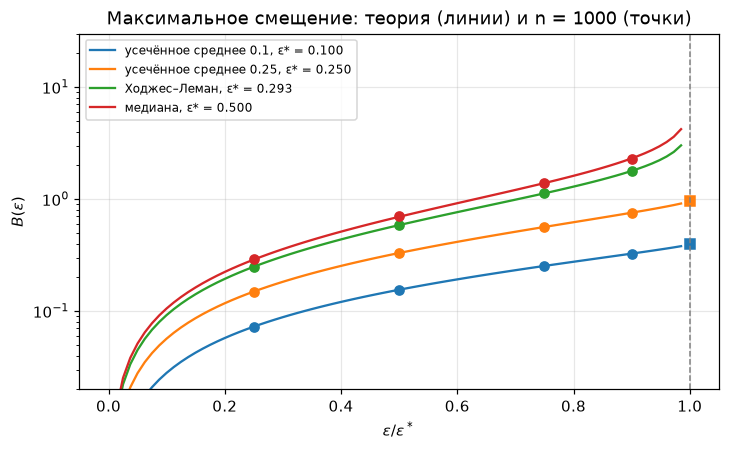

ε  B(ε), теория  смещение, n = 1000     SE
оценка                 ε/ε*                                                  
усечённое среднее 0.1  0.2500 0.0250        0.0725              0.0723 0.0010
                       0.5000 0.0500        0.1547              0.1546 0.0015
                       0.7500 0.0750        0.2524              0.2517 0.0020
                       0.9000 0.0900        0.3251              0.3244 0.0023
усечённое среднее 0.25 0.2500 0.0620        0.1478              0.1479 0.0018
                       0.5000 0.1250        0.3293              0.3307 0.0028
                       0.7500 0.1880        0.5645              0.5662 0.0038
                       0.9000 0.2250        0.7538              0.7553 0.0041
Ходжес–Леман           0.2500 0.0730        0.2476              0.2480 0.0019
                       0.5000 0.1460        0.5818              0.5821 0.0029
                       0.7500 0.2200        1.1266              1.1262 0.0043
                       0.9000 0.2640        1.7895              1.7808 0.0068
медиана                0.2500 0.1250        0.2877              0.2919 0.0043
                       0.5000 0.2500        0.6931              0.6979 0.0064
                       0.7500 0.3750        1.3863              1.3820 0.0101
                       0.9000 0.4500        2.3026              2.2941 0.0148

In [12]:
def F2(s):
    return LOGIS.expect(lambda y: LOGIS.cdf(s - y))


def int_logit(v):
    return special.xlogy(v, v) + special.xlogy(1 - v, 1 - v)


def max_bias_inf(name, eps):
    if eps > BP[name]:
        return np.inf
    if name in TRIM2:
        a = TRIM2[name]
        return (1 - eps) / (1 - 2 * a) * (int_logit((1 - a) / (1 - eps)) - int_logit(a / (1 - eps)))
    if name == "медиана":
        return LOGIS.ppf(0.5 / (1 - eps))
    p = 0.5 / (1 - eps) ** 2
    return np.inf if p >= 1 else 0.5 * optimize.brentq(lambda s: F2(s) - p, -1.0, 200.0, xtol=1e-12)


assert abs(F2(0.0) - 0.5) < 1e-12
assert all(abs(max_bias_inf(name, 0.0)) < 1e-9 for name in EST2)
assert np.isinf(max_bias_inf("медиана", 0.5))
for _name, _a in TRIM2.items():
    _r = _a / (1 - _a)
    assert abs(max_bias_inf(_name, _a) + (1 - _a) / (1 - 2 * _a) * int_logit(_r)) < 1e-12

_Z = LOGIS.rvs((100, 1000), rng_for(24))
_rows = []
for name, est in EST2.items():
    clean = est(MU + _Z)
    for r in (0.25, 0.5, 0.75, 0.9):
        m = int(round(r * BP[name] * 1000))
        X = MU + _Z
        X[:, :m] = MU + 1e6
        diff = est(X) - clean
        _rows.append({
            "оценка": name,
            "ε/ε*": r,
            "ε": m / 1000,
            "B(ε), теория": max_bias_inf(name, m / 1000),
            "смещение, n = 1000": diff.mean(),
            "SE": diff.std(ddof=1) / np.sqrt(len(diff)),
        })
mb_check = pd.DataFrame(_rows)
assert (abs(mb_check["смещение, n = 1000"] - mb_check["B(ε), теория"]) < 4 * mb_check["SE"]).all()

_rel = np.linspace(0, 0.985, 80)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, name in enumerate(EST2):
    _b = [max_bias_inf(name, r * BP[name]) for r in _rel]
    ax.plot(_rel, _b, color=f"C{i}", label=f"{name}, ε* = {BP[name]:.3f}")
    d = mb_check[mb_check["оценка"] == name]
    ax.plot(d["ε/ε*"], d["смещение, n = 1000"], "o", color=f"C{i}")
    if np.isfinite(max_bias_inf(name, BP[name])):
        ax.plot([1], [max_bias_inf(name, BP[name])], "s", color=f"C{i}")
ax.set_yscale("log")
ax.set_ylim(0.02, 30)
ax.axvline(1, color="gray", ls="--", lw=1)
ax.set_xlabel(r"$\varepsilon / \varepsilon^*$")
ax.set_ylabel(r"$B(\varepsilon)$")
ax.set_title("Максимальное смещение: теория (линии) и n = 1000 (точки)")
ax.legend(fontsize=8, loc="upper left")
plt.show()
mb_check.set_index(["оценка", "ε/ε*"])

Ниже точки срыва смещение ограничено, но может быть велико по сравнению со статистической погрешностью $\sqrt{v^2/n}$. Доля выбросов, при которой максимальное смещение оценки Ходжеса–Лемана сравнивается со стандартной ошибкой:

In [13]:
EPS_SE = {
    n: optimize.brentq(lambda e, n=n: max_bias_inf("Ходжес–Леман", e) - np.sqrt(V2["Ходжес–Леман"] / n), 1e-6, 0.29, xtol=1e-10)
    for n in (100, 1000)
}
pd.DataFrame({
    "стандартная ошибка √(v²/n)": {n: np.sqrt(V2["Ходжес–Леман"] / n) for n in EPS_SE},
    "ε: B(ε) = √(v²/n)": EPS_SE,
    "ε / ε*": {n: e / BP["Ходжес–Леман"] for n, e in EPS_SE.items()},
}).rename_axis("n")

,стандартная ошибка √(v²/n),ε: B(ε) = √(v²/n),ε / ε*
n,,,
100,0.1732,0.0530,0.1809
1000,0.0548,0.0178,0.0607


Теоретические кривые $B(\varepsilon)$ совпадают со смещениями при $n = 1000$ в пределах статистической погрешности (отклонения не больше 1.3 стандартной ошибки; смещение оценивается как разность оценок по засорённой и исходной выборке, что убирает общий случайный шум). На оси абсцисс — отношение $\varepsilon/\varepsilon^*$. У медианы и оценки Ходжеса–Лемана максимальное смещение плавно растёт и неограниченно возрастает при $\varepsilon \to \varepsilon^*$. У усечённых средних оно остаётся конечным до самой точки срыва (квадраты на графике: 0.39 и 0.95), а при $\varepsilon > \alpha$ срыв происходит скачком: пока $\varepsilon \le \alpha$, в усечённое среднее попадают только хорошие наблюдения, хотя и всё более крайние, а при $\varepsilon > \alpha$ — сами выбросы. Абсолютная величина смещения при одном и том же $\varepsilon/\varepsilon^*$ тем больше, чем больше сама точка срыва: при $\varepsilon/\varepsilon^* = 0.9$ от 0.33 у усечённого среднего с $\alpha = 0.1$ до 2.30 у медианы.

Для оценки Ходжеса–Лемана максимальное смещение сравнивается со стандартной ошибкой уже при $\varepsilon \approx 0.053$ ($n = 100$) и $\varepsilon \approx 0.018$ ($n = 1000$), т.е. при 18% и 6% от точки срыва. Чем больше выборка, тем меньшая доля выбросов делает смещение главной составляющей ошибки.

### 2.5. Доля дисперсии, объясняемая параметром

Генерируется $R = 2000$ выборок объёма $n = 100$: в $r$-й выборке $\mu_r \sim U(-5, 5)$, $X_i = \mu_r + U_i$, после чего первые $m$ наблюдений заменяются на одно и то же значение $A_r$, $\lg A_r \sim U(2, 4)$. Выбросы удалены от $\mu$ на $10^2$–$10^4$ и расположены независимо от $\mu$. Для $m = 0, 1, \dots, 60$ вычисляются $\rho^2 = \operatorname{corr}^2(T_n, \mu)$ и медиана $\lvert T_n - \mu\rvert$ по выборкам.

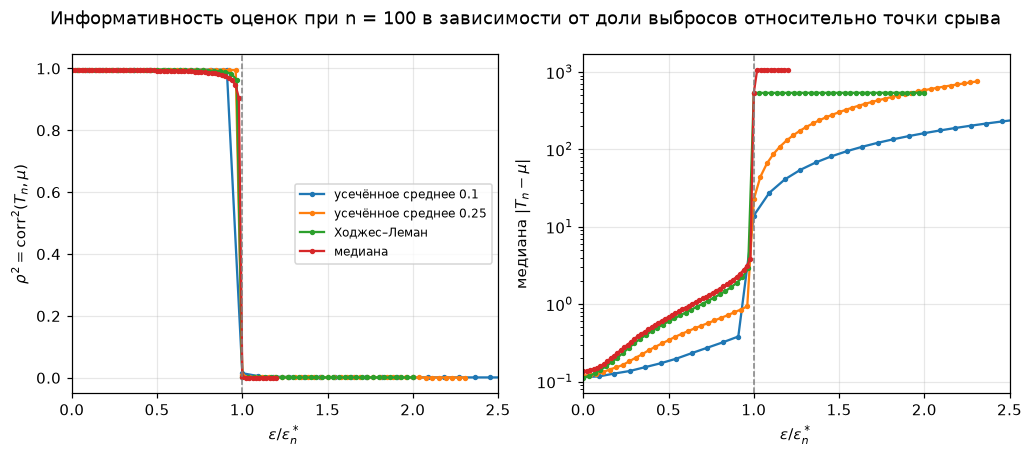

,m*,"ρ², m = 0","ρ², m = m*/2","ρ², m = m* − 1","ρ², m = m*","med|T−μ|, m* − 1","med|T−μ|, m*"
усечённое среднее 0.1,11.0000,0.9965,0.9964,0.9959,0.0149,0.3819,13.9720
усечённое среднее 0.25,26.0000,0.9963,0.9959,0.9943,0.0077,0.9379,22.6203
Ходжес–Леман,30.0000,0.9965,0.9955,0.9637,0.0011,2.9072,536.6472
медиана,50.0000,0.9953,0.9932,0.9042,0.0011,3.8607,540.5178


In [14]:
_rng = rng_for(25)
R2 = 2000
_mu = _rng.uniform(-5, 5, R2)
_A = 10 ** _rng.uniform(2, 4, R2)
_U = LOGIS.rvs((R2, N2), _rng)
_rows = []
for m in range(61):
    X = _mu[:, None] + _U
    X[:, :m] = _A[:, None]
    for name, est in EST2.items():
        t = est(X)
        _rows.append({"m": m, "оценка": name, "ρ²": np.corrcoef(t, _mu)[0, 1] ** 2, "med |T − μ|": np.median(np.abs(t - _mu))})
info = pd.DataFrame(_rows)
info["ε/ε*_n"] = info["m"] / N2 / info["оценка"].map(BP_N)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i, name in enumerate(EST2):
    d = info[info["оценка"] == name]
    axes[0].plot(d["ε/ε*_n"], d["ρ²"], marker="o", ms=2.5, color=f"C{i}", label=name)
    axes[1].semilogy(d["ε/ε*_n"], d["med |T − μ|"], marker="o", ms=2.5, color=f"C{i}", label=name)
for ax in axes:
    ax.axvline(1, color="gray", ls="--", lw=1)
    ax.set_xlim(0, 2.5)
    ax.set_xlabel(r"$\varepsilon / \varepsilon^*_n$")
axes[0].set_ylabel(r"$\rho^2 = \mathrm{corr}^2(T_n, \mu)$")
axes[1].set_ylabel(r"медиана $|T_n - \mu|$")
axes[0].legend(fontsize=8, loc="center right")
fig.suptitle("Информативность оценок при n = 100 в зависимости от доли выбросов относительно точки срыва")
plt.show()

_rows = {}
for name in EST2:
    m_star = int(round(BP_N[name] * N2))
    d = info[info["оценка"] == name].set_index("m")
    _rows[name] = {
        "m*": m_star,
        "ρ², m = 0": d.loc[0, "ρ²"],
        "ρ², m = m*/2": d.loc[m_star // 2, "ρ²"],
        "ρ², m = m* − 1": d.loc[m_star - 1, "ρ²"],
        "ρ², m = m*": d.loc[m_star, "ρ²"],
        "med|T−μ|, m* − 1": d.loc[m_star - 1, "med |T − μ|"],
        "med|T−μ|, m*": d.loc[m_star, "med |T − μ|"],
    }
info_tab = pd.DataFrame(_rows).T
assert (info_tab["ρ², m = m* − 1"] > 0.85).all() and (info_tab["ρ², m = m*"] < 0.05).all()
info_tab

Пока доля выбросов меньше точки срыва, $\rho^2 > 0.96$ (у медианы при $m = 48$ и $49$ — 0.95 и 0.90): оценка следует за параметром, хотя её смещение уже велико — при $m = m^* - 1$ медиана $\lvert T_n - \mu\rvert$ равна 2.9 у оценки Ходжеса–Лемана и 3.9 у медианы, в 17–19 раз больше стандартной ошибки. При $m = m^*$ доля объяснённой дисперсии скачком падает до $\rho^2 \approx 0.001$–$0.015$, а $\lvert T_n - \mu\rvert$ вырастает до десятков и сотен: значение оценки определяется положением выбросов $A_r$. Переход происходит при $\varepsilon/\varepsilon^*_n = 1$ у всех четырёх оценок, хотя их точки срыва различаются от 0.1 до 0.5. Сама величина $\rho^2$ за точкой срыва зависит от устройства эксперимента: она мала потому, что положение выбросов $A_r$ случайно и не связано с $\mu$. Устойчивый вывод — скачок при $m = m^*$: начиная с него значение оценки задают выбросы.

Итог задания 2: точка срыва — граница, за которой оценка полностью теряет информативность, её значение задают выбросы. Ниже точки срыва оценка информативна, но с точностью до максимального смещения $B(\varepsilon)$, которое у оценки Ходжеса–Лемана и медианы неограниченно растёт при $\varepsilon \to \varepsilon^*$. Поэтому практически полезная доля выбросов заметно меньше точки срыва и тем меньше, чем больше объём выборки.